# Clasificarea automată a produselor pe categorii

**Obiectiv:** prezicem categoria pornind numai de la titlul produsului și de la caracteristici derivate din acesta. Analizăm datele, prevenim scurgerea de informație între train/test, comparăm **două modele în două variante** (TF-IDF singur și TF-IDF + caracteristici) și justificăm modelul salvat. Acest notebook poate fi executat și în Colab, cu CSV-ul încărcat prin Files.

In [1]:
from pathlib import Path
import json
import pickle
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

pd.set_option("display.max_colwidth", 80)

## 1. Încărcare și analiză inițială

CSV-ul primit conține spații la începutul unor nume de coloane (` Category Label`, ` Listing Date  `). Le eliminăm **imediat după citire**; altfel accesarea coloanelor produce `KeyError`. Dacă lucrezi în Colab, încarcă CSV-ul în panoul **Fișiere**.

In [2]:
filename = "IMLP6_TASK_03-products.csv"
candidates = [Path("data") / filename, Path(filename), Path("/content") / filename]
csv_path = next((p for p in candidates if p.is_file()), None)
if csv_path is None:
    raise FileNotFoundError("Încarcă IMLP6_TASK_03-products.csv în Colab sau pune-l în data/.")
raw = pd.read_csv(csv_path)
raw.columns = raw.columns.str.strip()
print("Dataset original:", raw.shape)
print("Coloane după eliminarea spațiilor:", raw.columns.tolist())
print("Valori lipsă:")
display(raw.isna().sum().to_frame("lipsă"))
print("Categorii originale:")
display(raw["Category Label"].value_counts(dropna=False).to_frame("produse"))
display(raw.head())

Dataset original: (35311, 8)
Coloane după eliminarea spațiilor: ['product ID', 'Product Title', 'Merchant ID', 'Category Label', '_Product Code', 'Number_of_Views', 'Merchant Rating', 'Listing Date']
Valori lipsă:


,lipsă
product ID,0
Product Title,172
Merchant ID,0
Category Label,44
_Product Code,95
Number_of_Views,14
Merchant Rating,170
Listing Date,59


Categorii originale:


,produse
Category Label,
Fridge Freezers,5495
Washing Machines,4036
Mobile Phones,4020
CPUs,3771
TVs,3564
Fridges,3457
Dishwashers,3418
Digital Cameras,2696
Microwaves,2338


,product ID,Product Title,Merchant ID,Category Label,_Product Code,Number_of_Views,Merchant Rating,Listing Date
0,1,apple iphone 8 plus 64gb silver,1,Mobile Phones,QA-2276-XC,860.0,2.5,5/10/2024
1,2,apple iphone 8 plus 64 gb spacegrau,2,Mobile Phones,KA-2501-QO,3772.0,4.8,12/31/2024
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim free smartphone in gold,3,Mobile Phones,FP-8086-IE,3092.0,3.9,11/10/2024
3,4,apple iphone 8 plus 64gb space grey,4,Mobile Phones,YI-0086-US,466.0,3.4,5/2/2022
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked sim free,5,Mobile Phones,NZ-3586-WP,4426.0,1.6,4/12/2023


## 2. Curățarea datelor și prevenirea supraestimării performanței

Eliminăm titlurile/categoriile lipsă, standardizăm variantele `CPU`/`CPUs`, `Mobile Phone`/`Mobile Phones` și `fridge`/`Fridges`. Unele titluri apar de mai multe ori; dacă același titlu are categorii contradictorii, eliminăm toate înregistrările corespunzătoare. Păstrăm un singur rând pentru fiecare titlu (ignorând diferența dintre majuscule și minuscule). Altfel, același produs poate intra și în train, și în test, crescând artificial scorul.

Rânduri cu titlu etichetat contradictoriu: 4
Produse valide cu titlu unic: 30822
Număr de categorii: 10


,produse
Category Label,
Fridge Freezers,4808
Mobile Phones,3662
Washing Machines,3402
TVs,3275
Fridges,3188
CPUs,3043
Dishwashers,3042
Digital Cameras,2405
Microwaves,2094


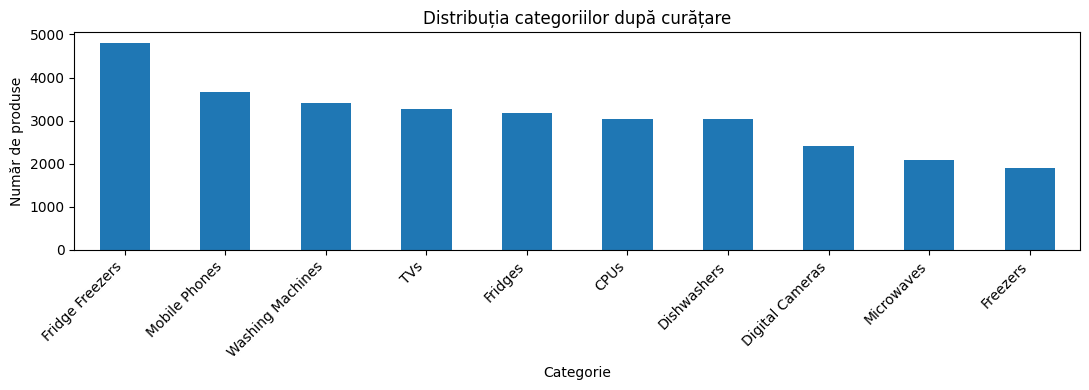

In [3]:
CATEGORY_RENAMES = {
    "cpu": "CPUs", "cpus": "CPUs",
    "mobile phone": "Mobile Phones", "mobile phones": "Mobile Phones",
    "fridge": "Fridges", "fridges": "Fridges",
}

def clean_dataset(raw_data):
    data = raw_data.copy()
    data.columns = data.columns.str.strip()
    data = data.dropna(subset=["Product Title", "Category Label"]).copy()
    data["Product Title"] = data["Product Title"].astype(str).str.strip()
    data["Category Label"] = data["Category Label"].astype(str).str.strip()
    data = data[(data["Product Title"] != "") & (data["Category Label"] != "")].copy()
    normalized = data["Category Label"].str.casefold().map(CATEGORY_RENAMES)
    data["Category Label"] = normalized.fillna(data["Category Label"])
    data["normalized_title"] = data["Product Title"].str.casefold()
    conflicting = data.groupby("normalized_title")["Category Label"].transform("nunique") > 1
    print("Rânduri cu titlu etichetat contradictoriu:", int(conflicting.sum()))
    data = data[~conflicting].copy()
    data = data.drop_duplicates(subset=["normalized_title"], keep="first")
    return data.drop(columns="normalized_title").reset_index(drop=True)

df = clean_dataset(raw)
print("Produse valide cu titlu unic:", len(df))
print("Număr de categorii:", df["Category Label"].nunique())
display(df["Category Label"].value_counts().to_frame("produse"))
fig, ax = plt.subplots(figsize=(11, 4))
df["Category Label"].value_counts().plot(kind="bar", ax=ax)
ax.set(title="Distribuția categoriilor după curățare", xlabel="Categorie", ylabel="Număr de produse")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 3. Ingineria caracteristicilor (feature engineering)

Folosim șase caracteristici calculabile din titlu, atât pentru produsele din CSV, cât și pentru titlurile introduse ulterior. Vom evalua **experimental** dacă adăugarea lor îmbunătățește F1 macro față de varianta exclusiv TF-IDF; nu presupunem că sunt automat utile.

In [4]:
NUMERIC_FEATURES = ["title_length", "word_count", "digit_count",
                    "special_char_count", "uppercase_count", "longest_word_length"]
FEATURE_COLUMNS = ["Product Title", *NUMERIC_FEATURES]

def create_features(raw_data):
    data = raw_data.copy()
    title = data["Product Title"].fillna("").astype(str)
    data["title_length"] = title.str.len()
    data["word_count"] = title.str.split().str.len()
    data["digit_count"] = title.apply(lambda s: sum(ch.isdigit() for ch in s))
    data["special_char_count"] = title.apply(
        lambda s: sum(not ch.isalnum() and not ch.isspace() for ch in s))
    data["uppercase_count"] = title.apply(lambda s: sum(ch.isupper() for ch in s))
    data["longest_word_length"] = title.apply(
        lambda s: max((len(word) for word in s.split()), default=0))
    return data

df = create_features(df)
display(df[["Product Title", *NUMERIC_FEATURES, "Category Label"]].head())
display(df[NUMERIC_FEATURES].describe())

,Product Title,title_length,word_count,digit_count,special_char_count,uppercase_count,longest_word_length,Category Label
0,apple iphone 8 plus 64gb silver,31,6,3,0,0,6,Mobile Phones
1,apple iphone 8 plus 64 gb spacegrau,35,7,3,0,0,9,Mobile Phones
2,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim free smartphone in gold,70,13,9,2,0,10,Mobile Phones
3,apple iphone 8 plus 64gb space grey,35,7,3,0,0,6,Mobile Phones
4,apple iphone 8 plus gold 5.5 64gb 4g unlocked sim free,54,11,6,1,0,8,Mobile Phones


,title_length,word_count,digit_count,special_char_count,uppercase_count,longest_word_length
count,30822.000000,30822.000000,30822.000000,30822.000000,30822.0,30822.000000
mean,52.761242,8.649731,6.816624,0.285705,0.0,9.785186
std,22.622348,4.215699,4.433567,0.624757,0.0,2.639525
min,5.000000,1.000000,0.000000,0.000000,0.0,2.000000
25%,38.000000,6.000000,4.000000,0.000000,0.0,8.000000
50%,51.000000,8.000000,6.000000,0.000000,0.0,10.000000
75%,65.000000,11.000000,9.000000,0.000000,0.0,11.000000
max,200.000000,37.000000,54.000000,9.000000,0.0,33.000000


## 4. Împărțirea train/test fără scurgere de informație

Împărțim după curățare și eliminarea duplicatelor: 80% antrenare, 20% testare, `random_state=42`, `stratify=y`. Învățarea vocabularului TF-IDF și scalarea numerică se fac **doar pe train** datorită `Pipeline`.

In [5]:
X = df[FEATURE_COLUMNS]
y = df["Category Label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
print(f"Train: {len(X_train)} produse | Test: {len(X_test)} produse")
print("Categorii train / test:", y_train.nunique(), y_test.nunique())

Train: 24657 produse | Test: 6165 produse
Categorii train / test: 10 10


## 5. TF-IDF, două modele și testarea utilității caracteristicilor

Comparăm **Logistic Regression** și **Linear SVC**; fiecare rulează cu TF-IDF simplu și cu TF-IDF + cele șase caracteristici. Metricile sunt calculate pe aceleași date de test. Alegerea se face prin **F1 macro**, astfel încât toate categoriile să aibă o pondere egală în criteriul principal.

In [6]:
def create_preprocessor(use_numeric):
    steps = [("text", TfidfVectorizer(lowercase=True, ngram_range=(1, 2),
                                     min_df=2, max_features=18000), "Product Title")]
    if use_numeric:
        steps.append(("numeric", StandardScaler(with_mean=False), NUMERIC_FEATURES))
    return ColumnTransformer(steps)

algorithms = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Linear SVC": LinearSVC(class_weight="balanced", random_state=42, max_iter=5000),
}
results = []
trained_models = {}
for use_numeric in (False, True):
    for name, algorithm in algorithms.items():
        variant = f"{name} + " + ("features" if use_numeric else "TF-IDF only")
        pipeline = Pipeline([
            ("preprocessor", create_preprocessor(use_numeric)),
            ("model", clone(algorithm)),
        ])
        pipeline.fit(X_train, y_train)
        predicted = pipeline.predict(X_test)
        scores = {
            "Model": variant,
            "Accuracy": accuracy_score(y_test, predicted),
            "Precision macro": precision_score(y_test, predicted, average="macro", zero_division=0),
            "Recall macro": recall_score(y_test, predicted, average="macro", zero_division=0),
            "F1 macro": f1_score(y_test, predicted, average="macro", zero_division=0),
            "F1 weighted": f1_score(y_test, predicted, average="weighted", zero_division=0),
        }
        results.append(scores)
        trained_models[variant] = (pipeline, use_numeric, name)
        print("\n" + "=" * 60)
        print(variant)
        display(pd.DataFrame([scores]).round(4))
        print(classification_report(y_test, predicted, zero_division=0))


Logistic Regression + TF-IDF only


,Model,Accuracy,Precision macro,Recall macro,F1 macro,F1 weighted
0,Logistic Regression + TF-IDF only,0.9509,0.9515,0.954,0.9522,0.9511


                  precision    recall  f1-score   support

            CPUs       1.00      0.99      1.00       609
 Digital Cameras       1.00      1.00      1.00       481
     Dishwashers       0.92      0.96      0.94       608
        Freezers       0.90      0.93      0.92       381
 Fridge Freezers       0.96      0.89      0.92       962
         Fridges       0.83      0.90      0.86       638
      Microwaves       0.98      0.95      0.96       419
   Mobile Phones       0.97      0.99      0.98       732
             TVs       0.98      0.99      0.99       655
Washing Machines       0.98      0.94      0.96       680

        accuracy                           0.95      6165
       macro avg       0.95      0.95      0.95      6165
    weighted avg       0.95      0.95      0.95      6165




Linear SVC + TF-IDF only


,Model,Accuracy,Precision macro,Recall macro,F1 macro,F1 weighted
0,Linear SVC + TF-IDF only,0.9612,0.9637,0.9623,0.9628,0.9613


...

,Model,Accuracy,Precision macro,Recall macro,F1 macro,F1 weighted
0,Logistic Regression + features,0.9513,0.9515,0.9542,0.9526,0.9514


                  precision    recall  f1-score   support

            CPUs       1.00      0.99      1.00       609
 Digital Cameras       1.00      1.00      1.00       481
     Dishwashers       0.91      0.96      0.94       608
        Freezers       0.92      0.93      0.92       381
 Fridge Freezers       0.96      0.89      0.92       962
         Fridges       0.85      0.89      0.87       638
      Microwaves       0.97      0.95      0.96       419
   Mobile Phones       0.98      0.99      0.99       732
             TVs       0.97      0.99      0.98       655
Washing Machines       0.96      0.95      0.95       680

        accuracy                           0.95      6165
       macro avg       0.95      0.95      0.95      6165
    weighted avg       0.95      0.95      0.95      6165




Linear SVC + features


,Model,Accuracy,Precision macro,Recall macro,F1 macro,F1 weighted
0,Linear SVC + features,0.9633,0.9648,0.9645,0.9645,0.9633


                  precision    recall  f1-score   support

            CPUs       1.00      0.99      1.00       609
 Digital Cameras       1.00      1.00      1.00       481
     Dishwashers       0.92      0.97      0.94       608
        Freezers       0.94      0.94      0.94       381
 Fridge Freezers       0.95      0.93      0.94       962
         Fridges       0.90      0.90      0.90       638
      Microwaves       0.99      0.96      0.97       419
   Mobile Phones       0.99      1.00      0.99       732
             TVs       0.98      1.00      0.99       655
Washing Machines       0.98      0.95      0.96       680

        accuracy                           0.96      6165
       macro avg       0.96      0.96      0.96      6165
    weighted avg       0.96      0.96      0.96      6165



## 6. Interpretarea metricilor și alegerea modelului

- **Accuracy:** proporția totală de clasificări corecte.
- **Precision macro:** media preciziei pe toate categoriile.
- **Recall macro:** media proporției de produse identificate din fiecare categorie.
- **F1 macro:** echilibru între precision și recall pentru toate categoriile, tratate egal.
- **F1 weighted:** media F1 ponderată după numărul produselor din categorii.

Modelul cu cel mai mare F1 macro este ales conform criteriului declarat. Diferența dintre varianta TF-IDF și varianta cu feature engineering arată dacă cele șase caracteristici au fost utile în acest experiment.

,Model,Accuracy,Precision macro,Recall macro,F1 macro,F1 weighted
0,Linear SVC + features,0.9633,0.9648,0.9645,0.9645,0.9633
1,Linear SVC + TF-IDF only,0.9612,0.9637,0.9623,0.9628,0.9613
2,Logistic Regression + features,0.9513,0.9515,0.9542,0.9526,0.9514
3,Logistic Regression + TF-IDF only,0.9509,0.9515,0.9540,0.9522,0.9511


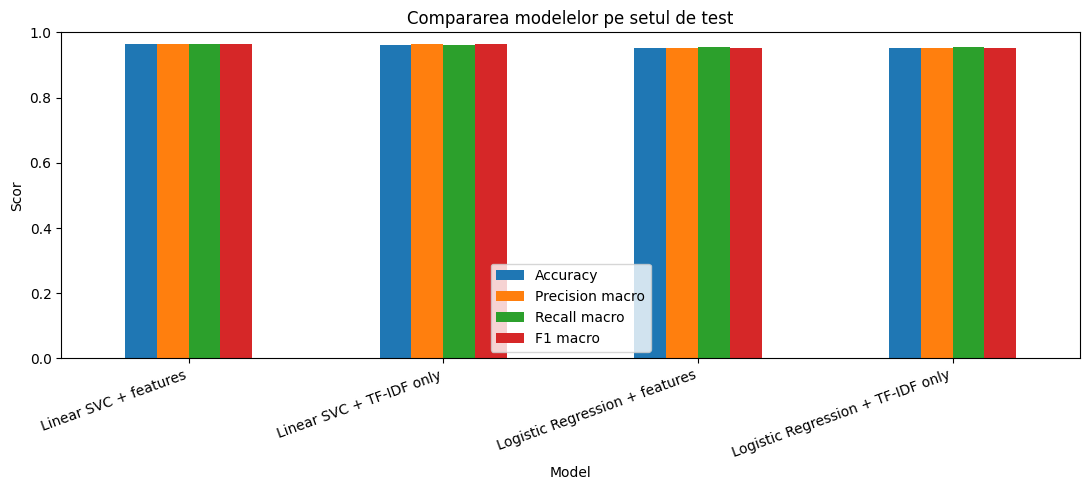

Modelul ales după F1 macro: Linear SVC + features
F1 macro: 0.9645
Efectul caracteristicilor suplimentare:
Logistic Regression: modificarea F1 macro = +0.0003
Linear SVC: modificarea F1 macro = +0.0017


In [7]:
results_df = pd.DataFrame(results).sort_values("F1 macro", ascending=False).reset_index(drop=True)
display(results_df.round(4))
ax = results_df.set_index("Model")[["Accuracy", "Precision macro", "Recall macro", "F1 macro"]].plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1), title="Compararea modelelor pe setul de test")
ax.set_ylabel("Scor")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()
best_name = results_df.iloc[0]["Model"]
best_pipeline, best_numeric, best_algorithm = trained_models[best_name]
print("Modelul ales după F1 macro:", best_name)
print("F1 macro:", round(results_df.iloc[0]["F1 macro"], 4))
print("Efectul caracteristicilor suplimentare:")
for algorithm in algorithms:
    base = next(s for s in results if s["Model"] == algorithm + " + TF-IDF only")
    extra = next(s for s in results if s["Model"] == algorithm + " + features")
    diff = extra["F1 macro"] - base["F1 macro"]
    print(algorithm + ": modificarea F1 macro = " + f"{diff:+.4f}")

## 7. Matricea de confuzie

Afișăm **toate categoriile**, fără să ascundem greșelile care ar fi în afara unui top 10. Pe diagonală apar predicțiile corecte; celulele din afara diagonalei arată confuziile modelului.

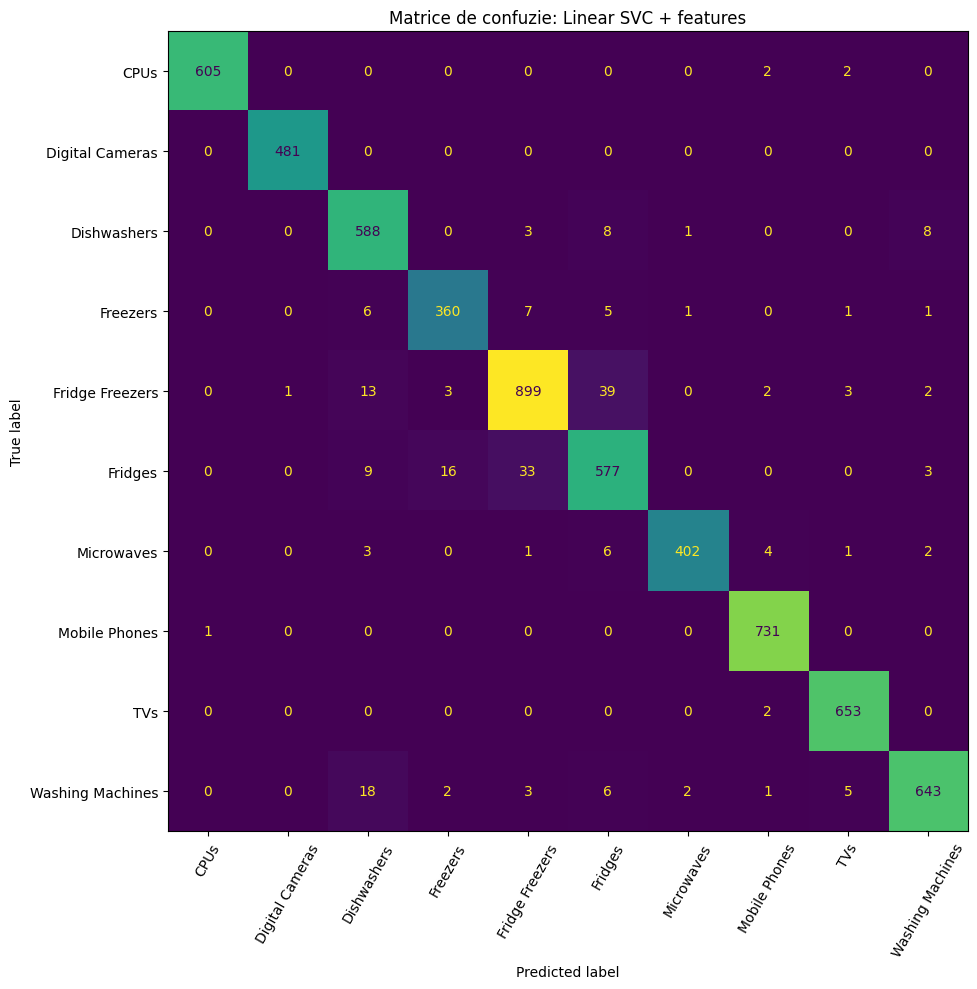

In [8]:
labels = sorted(y_test.unique())
y_pred_best = best_pipeline.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best, labels=labels)
fig, ax = plt.subplots(figsize=(11, 10))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, xticks_rotation=60,
                                                        values_format="d", colorbar=False)
ax.set_title("Matrice de confuzie: " + best_name)
plt.tight_layout()
plt.show()

## 8. Salvarea și reantrenarea modelului final

Scorurile raportate mai sus provin numai din setul de test. După alegere, **reantrenăm o copie proaspătă a modelului selectat pe toate produsele curate** și salvăm obiectul Pipeline, care conține și TF-IDF/scalarea. La încărcarea `.pkl` folosește numai fișiere proprii, de încredere, ideal cu aceeași versiune scikit-learn.

In [9]:
final_pipeline = Pipeline([
    ("preprocessor", create_preprocessor(best_numeric)),
    ("model", clone(algorithms[best_algorithm])),
])
final_pipeline.fit(X, y)
output_dir = Path("models")
output_dir.mkdir(parents=True, exist_ok=True)
model_path = output_dir / "product_classifier.pkl"
with model_path.open("wb") as stream:
    pickle.dump(final_pipeline, stream)
print("Model salvat:", model_path.resolve())

Model salvat: /mnt/data/product-category-classifier/models/product_classifier.pkl


## 9. Testare manuală pe exemplele cerute

Comparăm predicțiile cu categoriile așteptate din enunț. Nu schimbăm manual rezultatele dacă modelul greșește: astfel de erori sunt utile pentru analiza următoare.

In [10]:
def prepare_product(title):
    if not title.strip():
        raise ValueError("Titlul nu poate fi gol.")
    return create_features(pd.DataFrame({"Product Title": [title.strip()]}))[FEATURE_COLUMNS]

examples = [
    ("iphone 7 32gb gold,4,3,Apple iPhone 7 32GB", "Mobile Phones"),
    ("olympus e m10 mark iii geh use silber", "Digital Cameras"),
    ("kenwood k20mss15 solo", "Microwaves"),
    ("bosch wap28390gb 8kg 1400 spin", "Washing Machines"),
    ("bosch serie 4 kgv39vl31g", "Fridge Freezers"),
    ("smeg sbs8004po", "Fridge Freezers"),
]
checks = []
for title, expected in examples:
    pred = final_pipeline.predict(prepare_product(title))[0]
    checks.append({"Titlu": title, "Așteptat": expected, "Prezicere": pred, "Corect": pred == expected})
display(pd.DataFrame(checks))

,Titlu,Așteptat,Prezicere,Corect
0,"iphone 7 32gb gold,4,3,Apple iPhone 7 32GB",Mobile Phones,Mobile Phones,True
1,olympus e m10 mark iii geh use silber,Digital Cameras,Digital Cameras,True
2,kenwood k20mss15 solo,Microwaves,Microwaves,True
3,bosch wap28390gb 8kg 1400 spin,Washing Machines,Washing Machines,True
4,bosch serie 4 kgv39vl31g,Fridge Freezers,Fridge Freezers,True
5,smeg sbs8004po,Fridge Freezers,Fridges,False


## 10. Concluzii și limite

Tabelul de mai sus permite alegerea documentată a modelului prin **F1 macro**, nu doar prin acuratețe. Comparația cu varianta TF-IDF simplă verifică dacă feature engineering contribuie efectiv. Confuzia dintre categorii apropiate poate rămâne problematică; titlurile scurte sau incomplete nu oferă mereu informație suficientă.

**Limite importante:** scorurile provin dintr-o singură împărțire train/test; o evaluare viitoare poate include validare încrucișată, optimizarea hiperparametrilor și inspectarea manuală a clasificărilor greșite. Datele lipsă, etichetele inconsecvente și titlurile repetate au fost tratate înainte de antrenare. Modelul nu poate garanta categoria corectă pentru toate titlurile noi.